# TTE map with ABoVE boreal tree cover, 2000-2020

Runs the TTE workflow (`lib/tte_map.py`) with the yearly ABoVE boreal tree canopy cover
(Feng et al. 2022, *ABoVE: Tree Canopy Cover and Stand Age from Landsat, Boreal Forest Biome,
1984-2020*, ORNL DAAC, doi:10.3334/ORNLDAAC/2012) for each year from 2000 to 2020, on square
sites, and compares it with the original circa-2010 map (GEE `TTE_DATA_v201902v2`).

The ABoVE TCC is Landsat-based like the GFCC/Hansen inputs, but calibrated with reference data
from the boreal domain (including airborne lidar); its guide reports RMSE falling from 24.8 % to
16.4 % after that calibration. It covers 47-73 N, 30 m (0.00025 deg), one 2.5-degree tile per year.

**Reading the results.** The 2010 column is the like-for-like comparison with the reference. In
Eurasia the reference used Hansen 2010; in North America it used the lidar-calibrated
`cal_2m_tcc`. Other years show how the TTE pattern changes with the input year, which mixes real
change (forest gain, fire) with year-to-year noise in the yearly TCC.

**Earthdata access.** ABoVE, GFCC and Massey are NASA DAAC products, read directly from their
S3 buckets with temporary credentials. These come from maap-py if your MAAP account provides them,
otherwise from your Earthdata Login through `earthaccess`. The "Earthdata login" cell below asks for
your Earthdata username and password once and saves them in `~/.netrc` (readable only by you).
Without Earthdata access those columns are left blank with the reason.

## Two references

| Column | What it is | Made by |
|---|---|---|
| **Reference A: GEE script** | the published map `TTE_DATA_v201902v2` (circa 2010), as downloaded from GEE | `TTE _map_working` in GEE (Montesano et al. 2020) |
| **Reference B: Python script** | the TCC stored in the published map (its `tcc` band: `cal_2m_tcc` in North America, Hansen 2010 in Eurasia), classified again with `lib/tte_map.py` | the Python port |

Every other column is also the **Python script** (`lib/tte_map.py`), run with a different tree cover
input. Reference B is the Python script given (nearly) the GEE script's own input, so A vs B shows
what the port itself changes; B vs the other columns shows what the tree cover input changes.

**Zero floor.** Before the TTE workflow runs, ABoVE TCC values below 5 % are set to 0. The original
map's inputs (Hansen, `cal_2m_tcc`) are exactly 0 where there are no trees, and the TTE classes rely on
those zeros (TCC 0 with no change around is left out of the map; TCC 0 next to trees is the non-forest
edge), while the ABoVE TCC has a low non-zero background almost everywhere; the floor turns that
background back into "no trees".

*Side effect:* the sparse zone is TCC above 0 and up to 5 %, so with a 5 % floor only pixels at exactly
5 % stay sparse, and the sparse classes (1-4) nearly disappear in the floored runs.

## Why the Python script can differ from the GEE script

**Order of operations is the same.** In `TTE _map_working` the TCC is masked to the TTE domain
*before* the abruptness is computed (`tcc_data = tte_domain.where(..., tcc)`), water (GSW >= 1) is then
set to TCC 0 even outside the domain, abruptness is computed, and the result is masked to the domain
again and to `mask_abrupt` (TCC >= 0 and abruptness != 0). `tte_map.classify` does the same steps.

**Reference B (Python with the GEE map's TCC):**
1. *Resampled twice.* The GEE map (polar LAEA, 30 m) was downloaded on EPSG:4326 tiles (nearest);
   the Python script resamples it back to the polar grid (nearest). Some pixels are duplicated or
   dropped, which changes the slope, so abruptness and classes change pixel by pixel. This looks like
   the main cause of the 2-8 % disagreement: the disagreeing pixels are not concentrated next to
   clipped pixels.
2. *Already clipped.* The `tcc` band exists only where the map is classified. Unclassified domain pixels
   are filled with 0, which is right for "TCC 0 with no change around" (most of them) but wrong for
   the few pixels GEE left out for other reasons (masked abruptness at the domain edge, no-data in
   `cal_2m_tcc`); those become 0 and give their neighbours an edge.

**Any Python run:**
3. *Domain.* Read from the downloaded GEE tiles (EPSG:4326) and resampled back: edges move by a pixel
   in places (0.1-0.4 % of domain pixels).
4. *Hansen and GSW reads.* GEE read them through its pyramids (2x2 blocks north of ~64.07 N) with its
   own nearest-neighbour sampling; `tte_map.py` copies the pyramids, but 1-5 % of TCC pixels still
   differ (in stripes that follow GEE's internal tiles).
5. *Masked inputs.* In GEE, `image.where(test, value)` keeps the input where `value` is masked, so
   domain pixels with no TCC (e.g. no-data in `cal_2m_tcc`) took the domain value, 1, i.e. TCC 1 %.
   The Python script leaves them as no data. Small: <= 0.5 % of classified pixels are TCC 1 in class 1.
6. *Zones 3 and 4.* GEE split TCC > 30 % by the TCC relative error (Feng et al.); there is no such layer
   here, so zone 4 becomes 3. Both are class 9, so classes are unaffected; only `tte_zones` differs.
7. *Slope at edges.* `ee.Terrain.slope` and the numpy 4-neighbour slope may treat masked neighbours
   (domain edge, no data) differently.
8. *Class thresholds.* Abruptness exactly at -0.5, 0, 0.5 or 1 can fall on either side with float rounding.
9. *The comparison itself.* Agreement is counted on the GEE download grid, so the Python map is
   resampled once more (nearest) for counting.

**Python with Hansen (column "Hansen 2010") in North America** differs most for a different reason:
GEE used `cal_2m_tcc` there, not Hansen.

## 0. Setup

In [1]:
import os, sys, warnings
if os.path.isdir('/srv/conda/envs/notebook/share/proj'):
    os.environ.setdefault('PROJ_DATA', '/srv/conda/envs/notebook/share/proj')
warnings.filterwarnings('ignore', message='.*geographic CRS.*')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join(os.path.expanduser('~/code/tte'), 'lib'))
import tte_map as tm
import tte_tcc_sources as ts
import tte_compare as tc

### Earthdata login

Needed once per Hub home directory. If there is no `~/.netrc` (or `~/credentials.ini` with an
`[EarthData]` section), this asks for your Earthdata Login username and password and saves them
in `~/.netrc`. Then it checks that S3 credentials can be made for the ORNL and LP DAACs.

In [2]:
import earthaccess
if ts.earthdata_login() is None:
    try:
        earthaccess.login(strategy='interactive', persist=True)    # prompts; writes ~/.netrc
    except Exception as e:
        print('Earthdata login needs a prompt: run this cell in the notebook itself.', type(e).__name__)
for daac in ('ornl', 'lpdaac'):
    try:
        print(daac, 'S3 access OK' if ts.earthdata_options(daac)['scheme'] == 's3' else 'https access only')
    except Exception as e:
        print(daac, 'no access:', str(e)[:200])

ornl S3 access OK


lpdaac S3 access OK


## 1. Settings


* `SITES`: name -> (lon, lat) of the centre of a square, `SIZE_KM` on a side. Each is the most mixed
  15 km window (forest, treeline, tundra) of the reference map in its region: Alaska (3), Scandinavia (2),
  western Siberia (2), Taymyr (1) and eastern Siberia (2). Any place in the TTE domain works. Coverage notes: the ABoVE boreal TCC has no tiles north of 70 N in
  Taymyr (so none at Khatanga) or north of 67.5 N west of 162.5 W (so the Noatak site is on the
  lower river, inside its coverage); Massey is North America only.
* Results are saved per site and input in `OUT_DIR`, so a re-run only computes what is new
  (`REDO = True` recomputes).

* `YEARS`: years run through the TTE workflow; `MAP_YEARS`: the years shown as map columns
  (all of `YEARS` are used in the year-by-year plots).
* `FLOOR`: the zero floor (%), see above. Every year is run twice: ABoVE TCC as is, and with the floor.

In [3]:
SITES = {                                   # name: (lon, lat) of the square's centre
    'Eastern Seward Peninsula': (-161.84, 64.85),
    'Lower Noatak River':       (-162.25, 67.19),
    'Eastern Brooks Range':     (-145.71, 67.61),
    'Northern Scandinavia':     (25.55, 69.23),     # Finnmark / Utsjoki
    'Tornetrask, N Sweden':     (20.40, 68.33),
    'Lower Ob (Salekhard)':     (67.51, 66.12),     # western Siberia
    'Pur-Taz (Urengoy)':        (77.83, 66.36),     # western Siberia
    'Khatanga':                 (102.29, 72.07),    # Taymyr
    'Lower Indigirka':          (147.55, 69.83),    # eastern Siberia
    'Lower Kolyma':             (159.68, 68.10),    # eastern Siberia
}
SIZE_KM = 15

YEARS = list(range(2000, 2021))
MAP_YEARS = [2000, 2005, 2010, 2015, 2020]
FLOOR = 5                        # ABoVE TCC below this (%) set to 0 in the floored runs
OUT_DIR = os.path.expanduser('~/my-private-bucket/tte/compare_above_years')
REDO = False

REF_B = {'gee_tcc': dict(label='Ref. B: Python script\nwith the GEE map\'s TCC',
                         run=lambda tr, sh, lon, lat: ts.tcc_gee_tte(tr, sh, tc.gee_paths(lon, lat)))}
YEAR_SOURCES = {}
for y in YEARS:
    YEAR_SOURCES[f'above{y}'] = dict(label=f'ABoVE TCC {y}', year=y, floor=0,
                                     run=lambda tr, sh, lon, lat, y=y: ts.tcc_above_boreal(tr, sh, y))
    YEAR_SOURCES[f'above{y}_floor{FLOOR}'] = dict(
        label=f'ABoVE TCC {y}\nTCC < {FLOOR} % set to 0', year=y, floor=FLOOR,
        run=lambda tr, sh, lon, lat, y=y: ts.zero_floor(ts.tcc_above_boreal(tr, sh, y), FLOOR))
SOURCES = {**REF_B, **YEAR_SOURCES}

## 2. Run the TTE workflow for every site, year and floor

About 5-20 s per site, year and floor after the first (domain and water are read once per site).

In [4]:
STATUS = tc.run_sites(SITES, SOURCES, OUT_DIR, SIZE_KM, redo=REDO)

Tornetrask, N Sweden: grid (659, 671), 97% in the TTE domain (2s)


  above2020: no data at this site


  above2020_floor5: no data at this site


Pur-Taz (Urengoy): grid (624, 608), 93% in the TTE domain (3s)


  above2020: no data at this site


  above2020_floor5: no data at this site


... (22 outputs left out)

  above2020_floor5: no data at this site


Lower Indigirka: grid (710, 715), 87% in the TTE domain (2s)


  above2020: no data at this site


  above2020_floor5: no data at this site


In [5]:
DISP = tc.load_display(SITES, SOURCES, OUT_DIR, SIZE_KM)          # equal-area squares, for maps and areas
PIX = tc.load_pixel_maps(SITES, SOURCES, OUT_DIR, SIZE_KM)        # GEE tile pixels, for agreement
ALL = ['reference'] + list(SOURCES)
LABELS = {'reference': 'Ref. A: GEE script\npublished map c. 2010', **{k: v['label'] for k, v in SOURCES.items()}}
AGREE = tc.agreement_table(DISP, SITES, ALL, pixel_maps=PIX)
AGREE['year'] = AGREE.input.map(lambda k: YEAR_SOURCES[k]['year'] if k in YEAR_SOURCES else np.nan)
AGREE['floor'] = AGREE.input.map(lambda k: YEAR_SOURCES[k]['floor'] if k in YEAR_SOURCES else np.nan)
# each map year as is, then with the floor, side by side
MAP_COLUMNS = ['reference', 'gee_tcc'] + [k for y in MAP_YEARS for k in (f'above{y}', f'above{y}_floor{FLOOR}')]

## 3. Matrix: TTE classes

Rows are sites; Reference A (GEE script) and Reference B (Python script with the GEE map's TCC) are
on the left, then for each year in `MAP_YEARS` the ABoVE TCC as is and with the zero floor. GEE class
palette.

The two numbers in the lower left of each map compare that map with Reference A (the GEE map),
counted on the GEE map's own pixel grid:
* **same class**: of the pixels that both maps classify, the share that gets the same TTE class. It asks:
  where both maps see a forest structure pattern, is it the same pattern?
* **overlap**: pixels classified in both maps / pixels classified in either map. It asks: do the two maps
  classify the same places? 100 % = exactly the same footprint; it drops when one map classifies areas the
  other leaves out (e.g. tundra that the GEE map leaves unclassified).

A map can have a high overlap and a low same class (same places, different patterns), or the reverse.

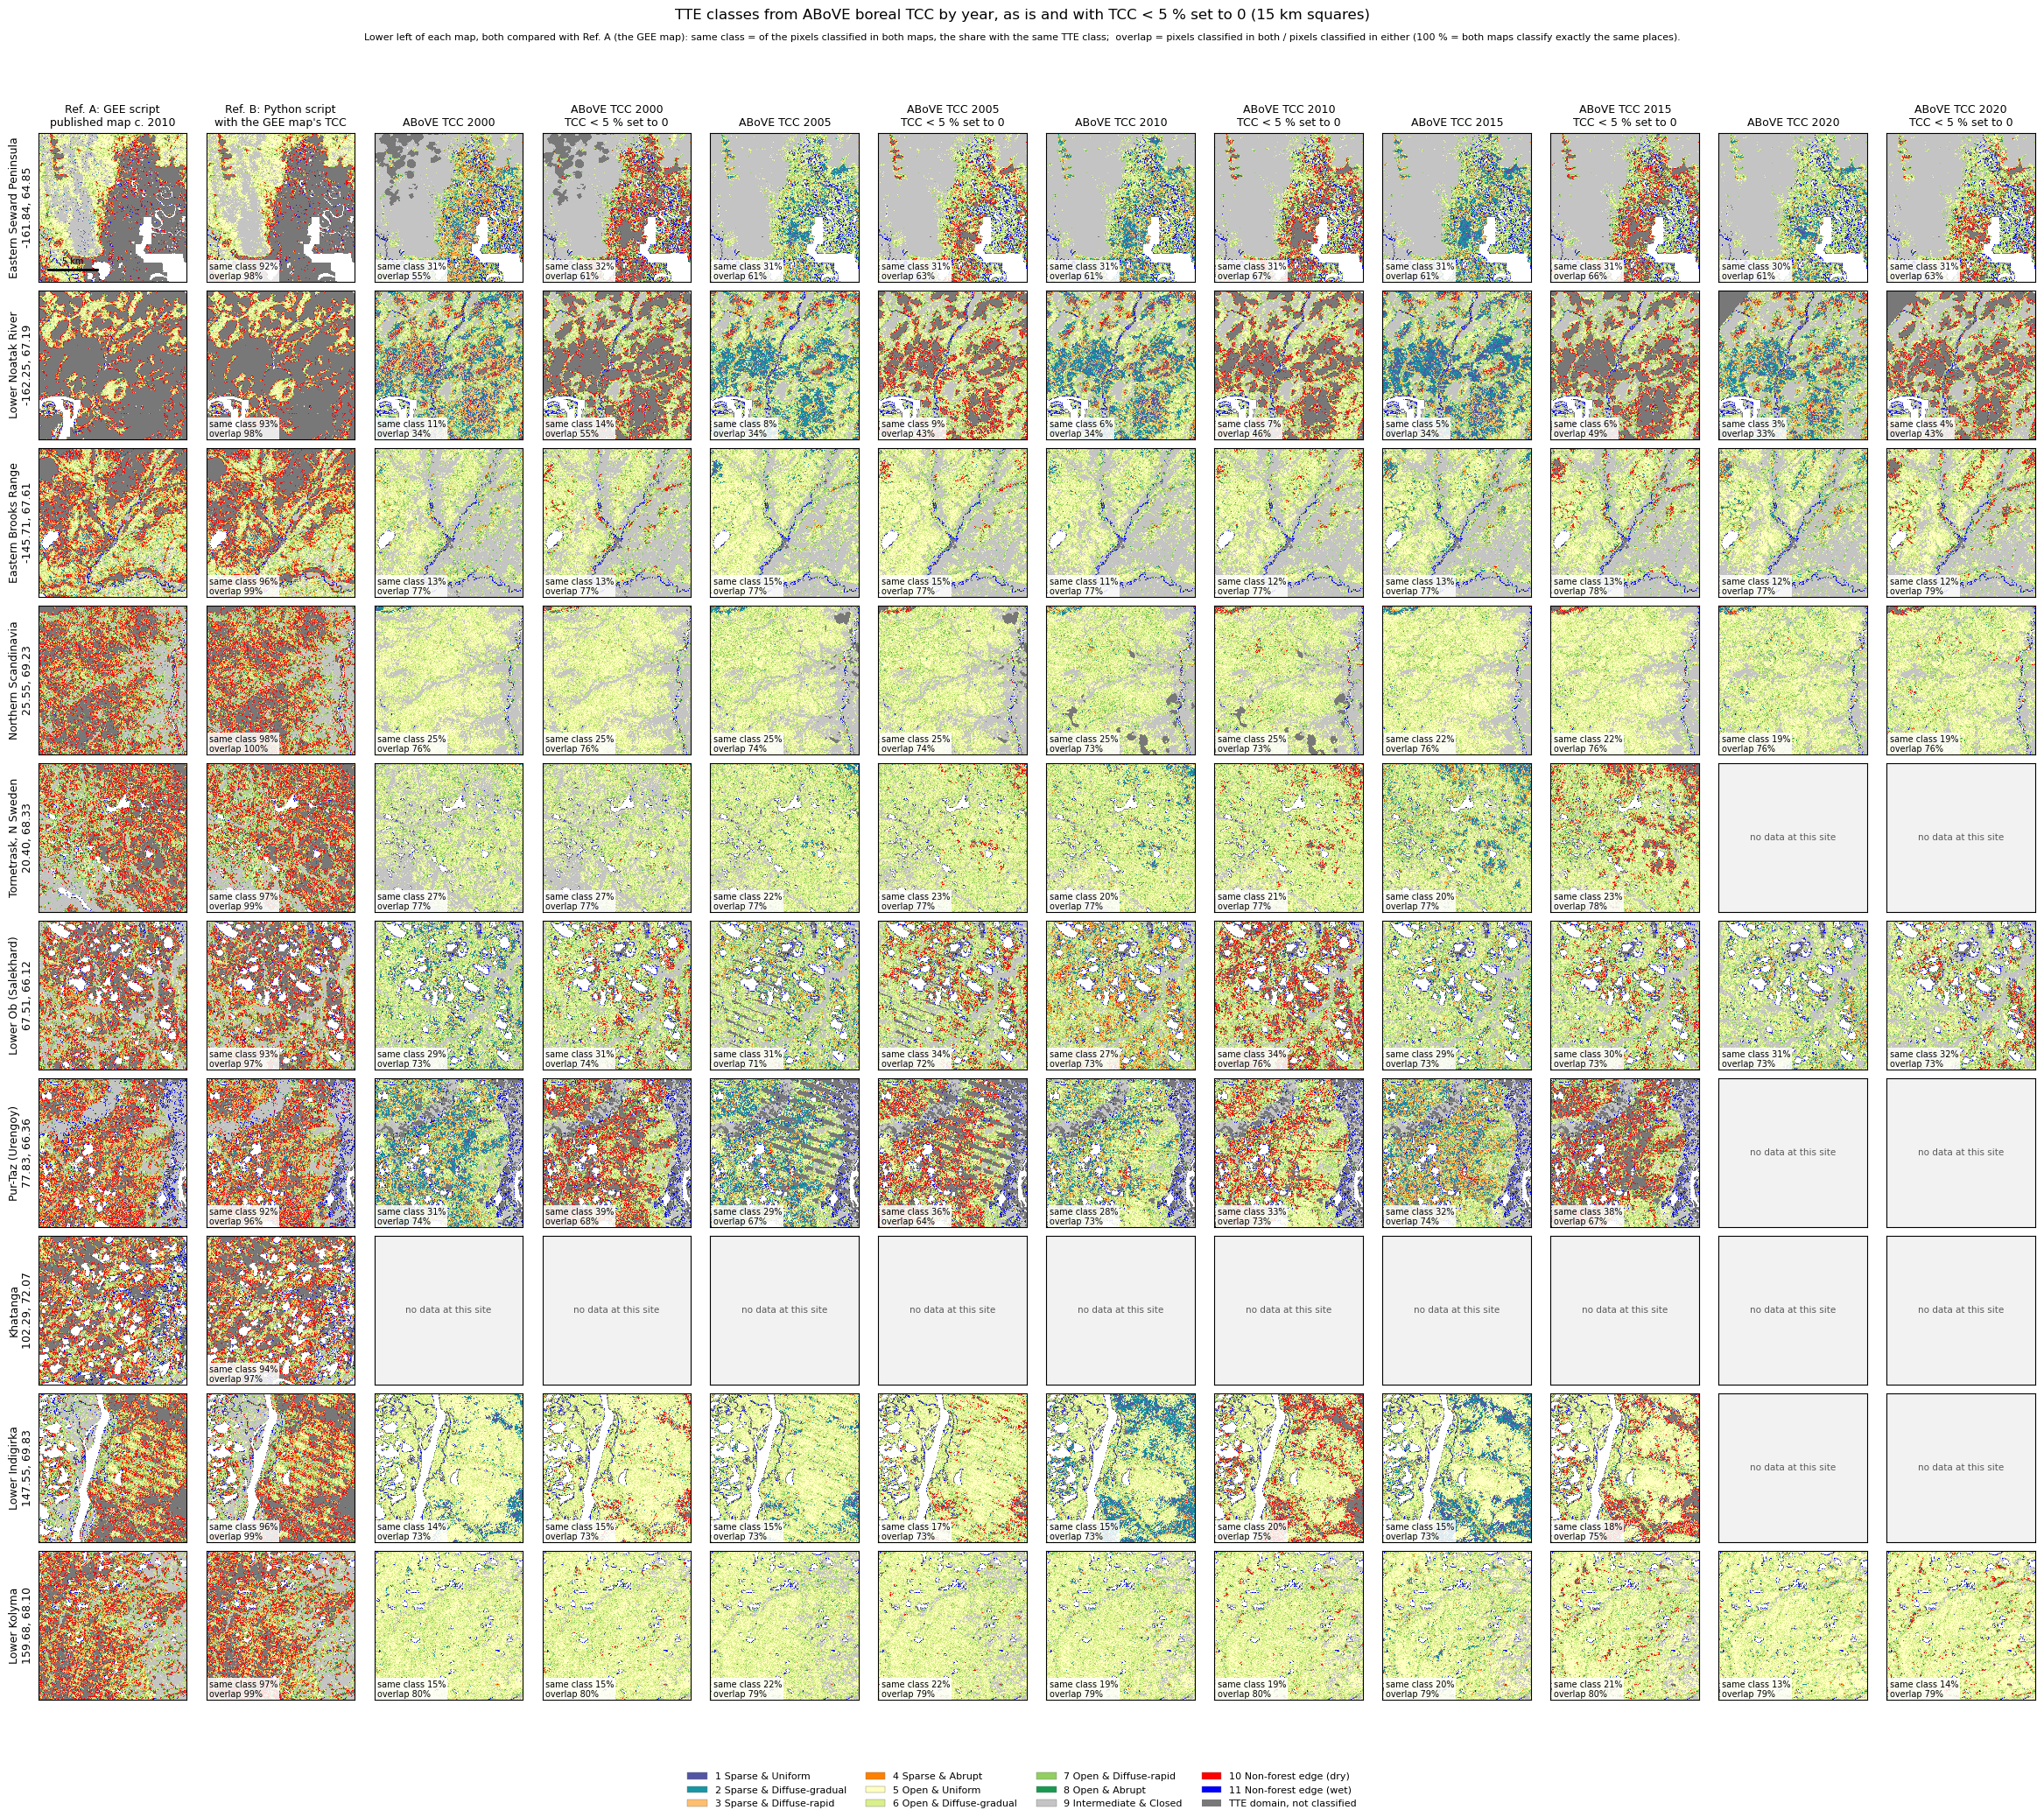

In [6]:
fig = tc.plot_matrix(DISP, SITES, MAP_COLUMNS, LABELS, SIZE_KM, status=STATUS, agree=AGREE, kind='classes', panel=1.9,
                     title=f'TTE classes from ABoVE boreal TCC by year, as is and with TCC < {FLOOR} % set to 0 ({SIZE_KM} km squares)')
plt.show()

## 4. Matrix: the ABoVE tree cover by year, as is and floored (0-50 %, GEE TCC palette; Ref. A = the GEE map's TCC)

/home/jovyan/code/tte/lib/tte_compare.py:362: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 1.15 / H, 1, 1 - top / H))


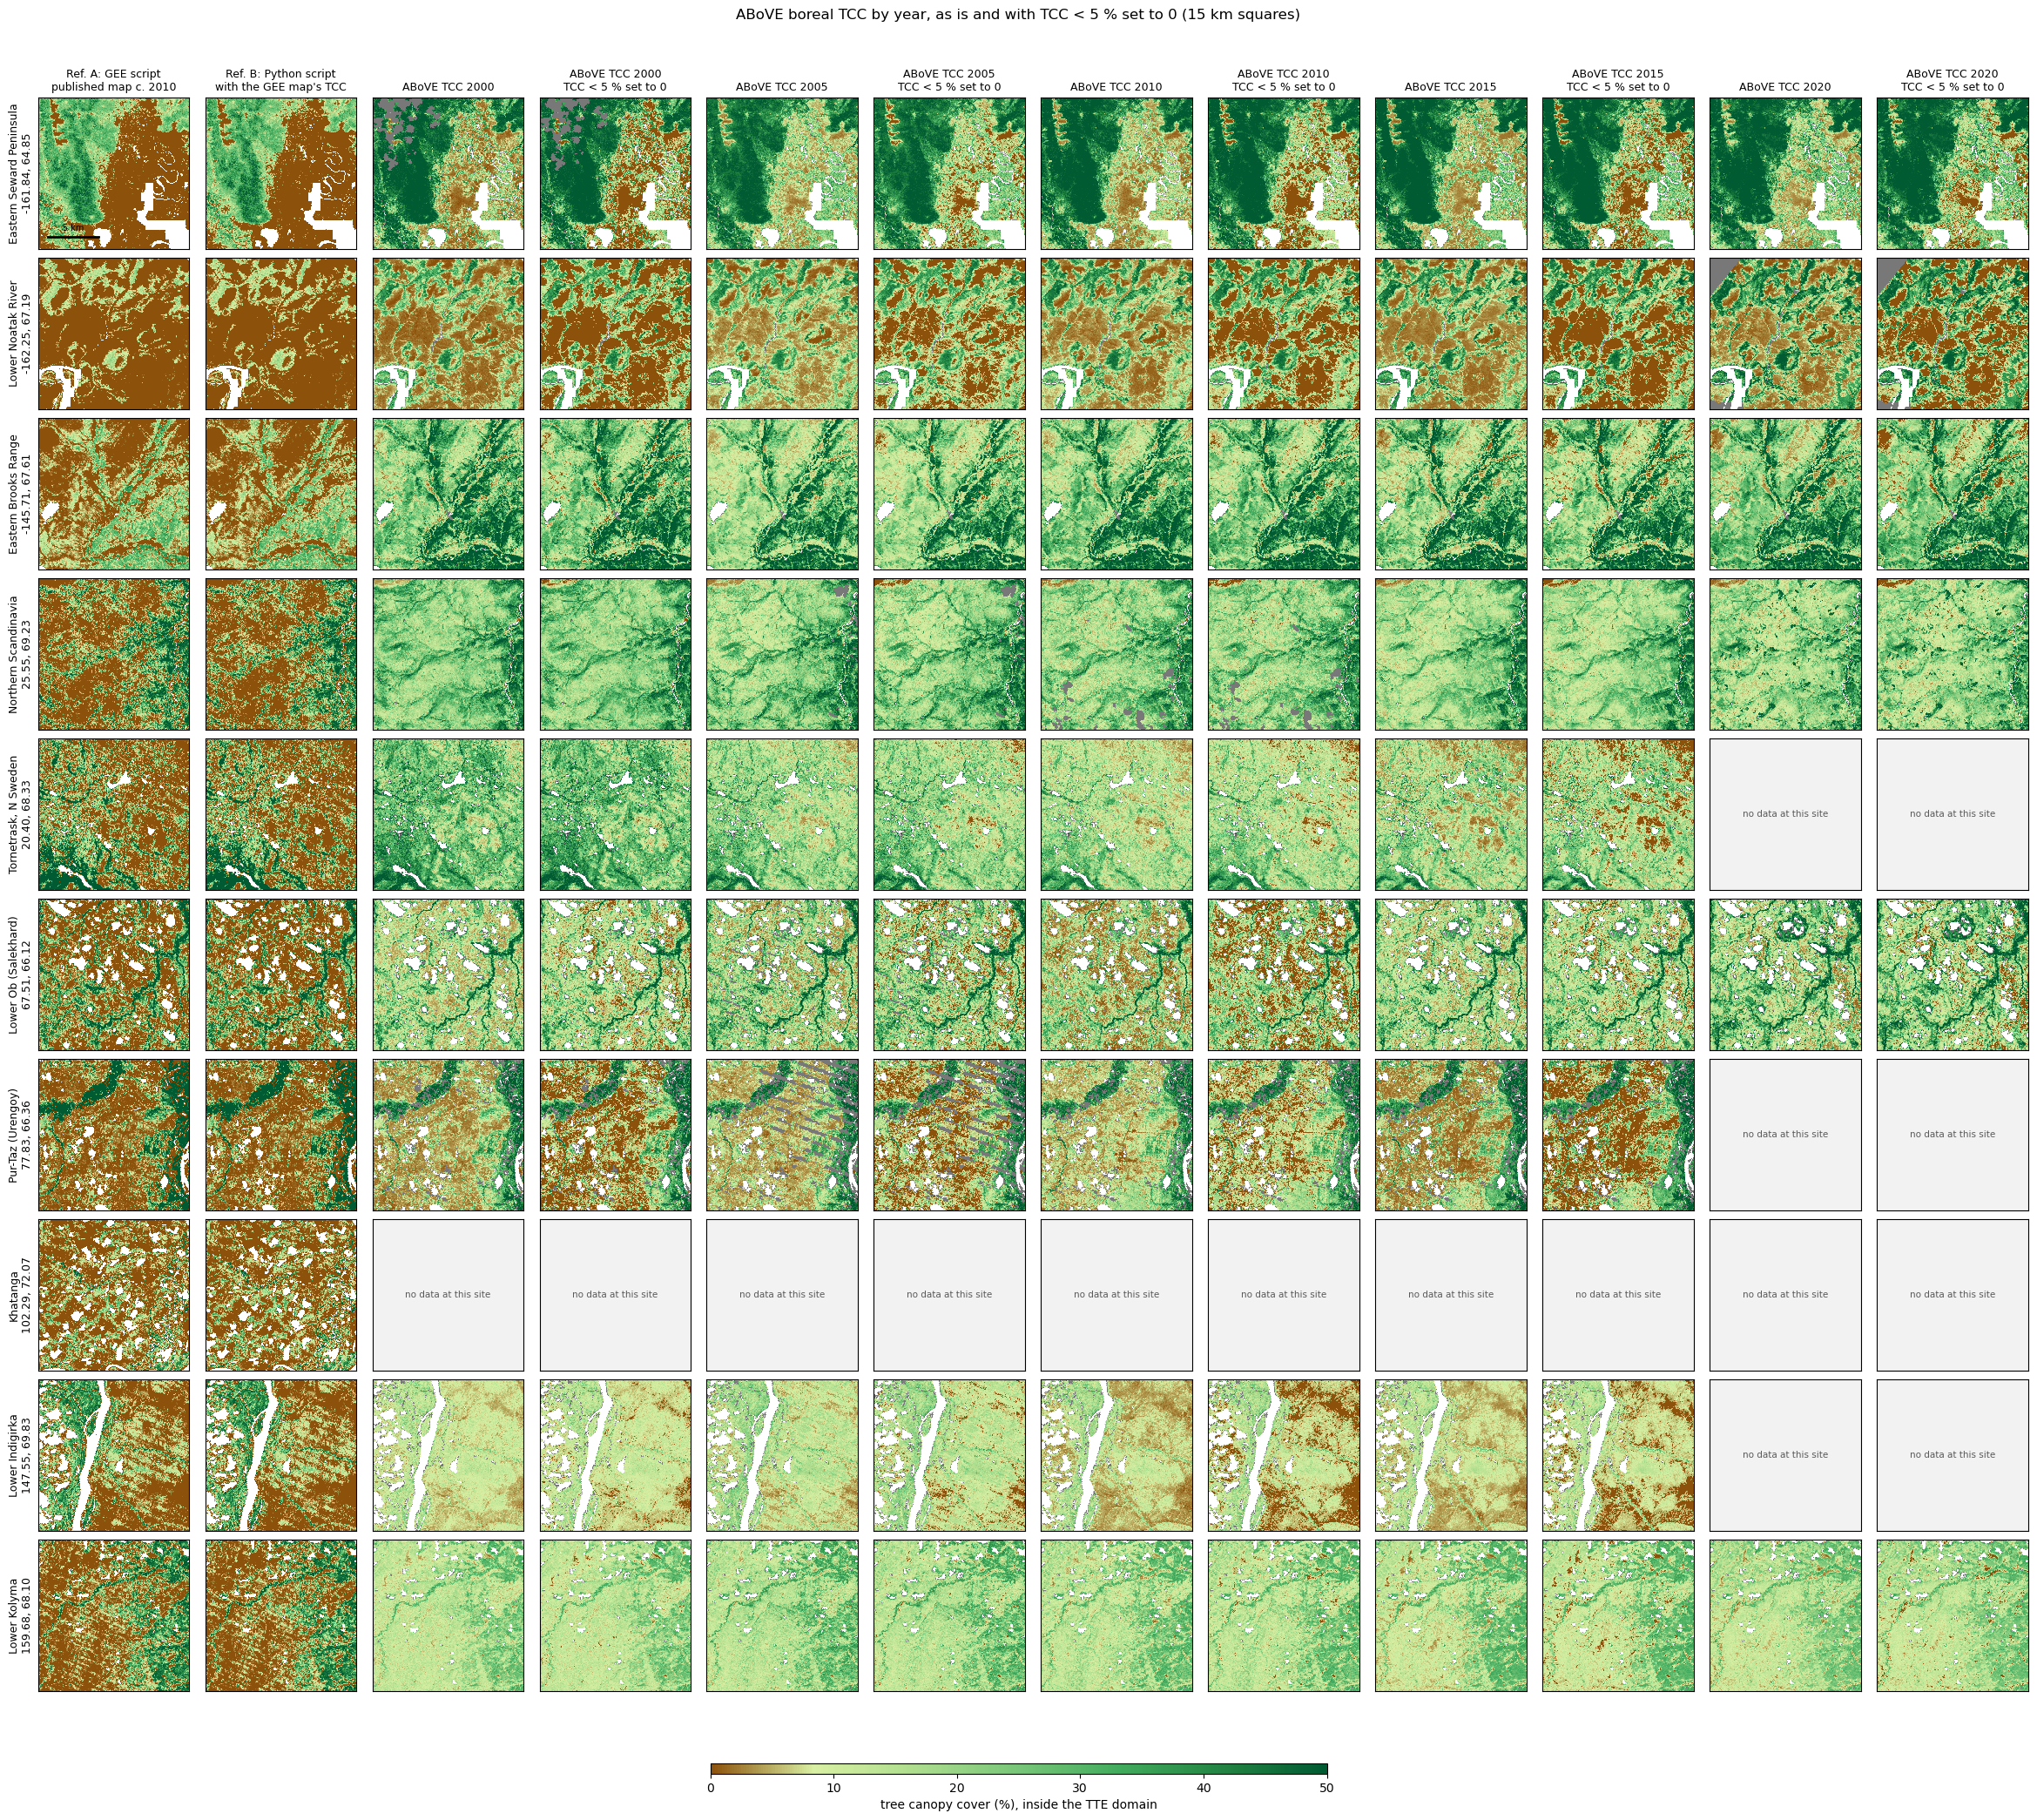

In [7]:
fig = tc.plot_matrix(DISP, SITES, MAP_COLUMNS, LABELS, SIZE_KM, status=STATUS, kind='tcc', panel=1.9,
                     title=f'ABoVE boreal TCC by year, as is and with TCC < {FLOOR} % set to 0 ({SIZE_KM} km squares)')
plt.show()

## 5. Year by year

For each site: area of each forest structure group (sparse, open, intermediate & closed,
non-forest edge), mean TCC in the domain, and agreement with Reference A. Circles and solid lines:
ABoVE TCC as is; triangles and thin lines: with the zero floor. Horizontal lines: Reference A (GEE
script, dashed) and Reference B (Python script, dotted).

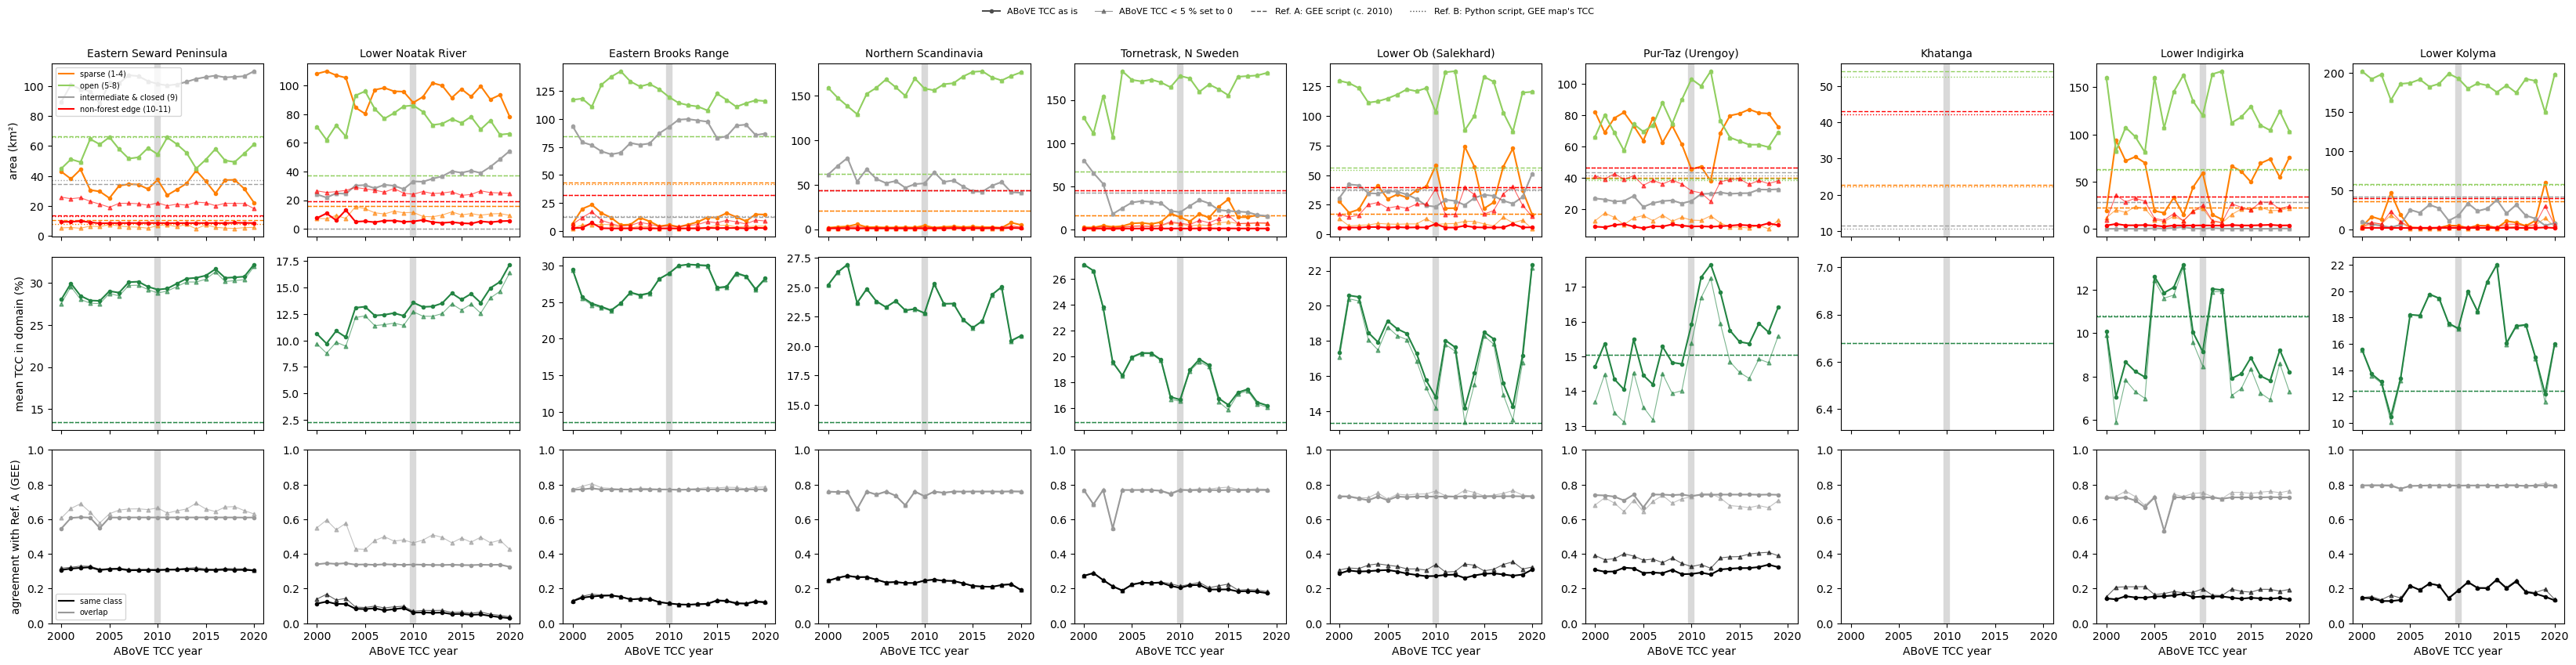

In [8]:
from matplotlib.lines import Line2D
GA = tc.group_areas(DISP, SITES, ALL)
STYLE = {0: dict(marker='o', ms=3, lw=1.5, alpha=1.0), FLOOR: dict(marker='^', ms=3.5, lw=0.8, alpha=0.6)}
fig, axes = plt.subplots(3, len(SITES), figsize=(3.3 * len(SITES), 8.5), sharex=True, squeeze=False)
for j, site in enumerate(SITES):
    g = GA[GA.site == site]
    yr = g[g.input.isin(list(YEAR_SOURCES))].assign(year=lambda d: d.input.map(lambda k: YEAR_SOURCES[k]['year']),
                                                    floor=lambda d: d.input.map(lambda k: YEAR_SOURCES[k]['floor']))
    ax = axes[0, j]
    for (grp, color) in zip(tc.GROUPS, tc.GROUP_COLORS):
        for fl, st in STYLE.items():
            s = yr[(yr.group == grp) & (yr.floor == fl)].sort_values('year')
            ax.plot(s.year, s.km2, color=color, **st)
        for k, ls in (('reference', '--'), ('gee_tcc', ':')):
            ref = g[(g.input == k) & (g.group == grp)].km2
            if len(ref):
                ax.axhline(ref.iloc[0], color=color, ls=ls, lw=1)
    ax.set_title(site, fontsize=10)
    for fl, st in STYLE.items():
        a = AGREE[(AGREE.site == site) & (AGREE.floor == fl)].sort_values('year')
        axes[1, j].plot(a.year, a.mean_tcc, color='#238443', **st)
        axes[2, j].plot(a.year, a.same_class, color='k', **st)
        axes[2, j].plot(a.year, a.overlap, color='0.6', **st)
    for k, ls in (('reference', '--'), ('gee_tcc', ':')):
        r = AGREE[(AGREE.site == site) & (AGREE.input == k)]
        if len(r):
            axes[1, j].axhline(r.mean_tcc.iloc[0], color='#238443', ls=ls, lw=1)
    axes[2, j].set_ylim(0, 1)
    for ax in axes[:, j]:
        ax.axvline(2010, color='0.85', lw=6, zorder=0)
axes[0, 0].set_ylabel('area (km²)')
axes[1, 0].set_ylabel('mean TCC in domain (%)')
axes[2, 0].set_ylabel('agreement with Ref. A (GEE)')
axes[0, 0].legend(handles=[Line2D([], [], color=c, label=gname) for gname, c in zip(tc.GROUPS, tc.GROUP_COLORS)],
                  fontsize=7, loc='upper left')
axes[2, 0].legend(handles=[Line2D([], [], color='k', label='same class'), Line2D([], [], color='0.6', label='overlap')],
                  fontsize=7, loc='lower left')
for ax in axes[2]:
    ax.set_xlabel('ABoVE TCC year')
fig.legend(handles=[Line2D([], [], color='0.3', label='ABoVE TCC as is', **STYLE[0]),
                    Line2D([], [], color='0.3', label=f'ABoVE TCC < {FLOOR} % set to 0', **STYLE[FLOOR]),
                    Line2D([], [], color='0.3', ls='--', lw=1, label='Ref. A: GEE script (c. 2010)'),
                    Line2D([], [], color='0.3', ls=':', lw=1, label="Ref. B: Python script, GEE map's TCC")],
           loc='upper center', ncol=4, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 6. Agreement with Reference A (GEE script) by year: as is, then with the zero floor

In [9]:
for fl, name in ((0, 'ABoVE TCC as is'), (FLOOR, f'ABoVE TCC < {FLOOR} % set to 0')):
    t = AGREE[AGREE.floor == fl].pivot(index='site', columns='year', values='same_class').reindex(list(SITES))
    t.columns = t.columns.astype(int)
    display(tc.styled(t, '{:.0%}', f'same class as Reference A: {name}'))

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
site,,,,,,,,,,,,,,,,,,,,,
Eastern Seward Peninsula,31%,32%,32%,32%,31%,31%,31%,31%,31%,31%,31%,31%,31%,31%,31%,31%,31%,31%,31%,31%,30%
Lower Noatak River,11%,12%,11%,11%,8%,8%,9%,7%,8%,9%,6%,6%,6%,6%,5%,5%,5%,5%,4%,3%,3%
Eastern Brooks Range,13%,15%,15%,16%,16%,15%,14%,14%,14%,12%,11%,11%,11%,11%,11%,13%,13%,11%,11%,13%,12%
Northern Scandinavia,25%,26%,27%,27%,27%,25%,24%,24%,23%,23%,25%,25%,24%,24%,23%,22%,21%,21%,22%,22%,19%
"Tornetrask, N Sweden",27%,29%,25%,21%,19%,22%,23%,23%,23%,22%,20%,22%,22%,19%,19%,20%,18%,19%,18%,17%,-
Lower Ob (Salekhard),29%,30%,30%,30%,30%,31%,30%,29%,28%,27%,27%,28%,28%,26%,28%,29%,29%,28%,27%,28%,31%
Pur-Taz (Urengoy),31%,30%,30%,32%,32%,29%,29%,29%,31%,28%,28%,29%,28%,31%,31%,32%,32%,32%,34%,32%,-
Khatanga,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
Lower Indigirka,14%,14%,16%,15%,15%,15%,16%,16%,17%,15%,15%,15%,15%,15%,14%,15%,14%,14%,15%,14%,-


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
site,,,,,,,,,,,,,,,,,,,,,
Eastern Seward Peninsula,32%,32%,33%,33%,31%,31%,32%,31%,31%,31%,31%,31%,31%,32%,32%,31%,31%,32%,31%,31%,31%
Lower Noatak River,14%,17%,13%,14%,9%,9%,10%,9%,9%,10%,7%,7%,7%,7%,6%,6%,6%,7%,5%,5%,4%
Eastern Brooks Range,13%,16%,17%,16%,16%,15%,14%,14%,14%,12%,12%,11%,11%,11%,12%,13%,13%,12%,12%,13%,12%
Northern Scandinavia,25%,26%,28%,27%,27%,25%,24%,24%,23%,23%,25%,25%,25%,24%,23%,22%,21%,21%,22%,23%,19%
"Tornetrask, N Sweden",27%,29%,25%,22%,19%,23%,24%,23%,24%,23%,21%,22%,24%,20%,22%,23%,19%,19%,19%,18%,-
Lower Ob (Salekhard),31%,32%,32%,34%,34%,34%,33%,31%,31%,31%,34%,30%,30%,34%,33%,30%,31%,34%,35%,31%,32%
Pur-Taz (Urengoy),39%,37%,37%,40%,39%,36%,37%,35%,38%,35%,33%,34%,32%,38%,38%,38%,40%,41%,41%,39%,-
Khatanga,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
Lower Indigirka,15%,21%,21%,21%,21%,17%,17%,18%,18%,18%,20%,16%,16%,20%,18%,18%,20%,20%,19%,20%,-


## 7. Class composition (References A and B, and map years as is and floored)

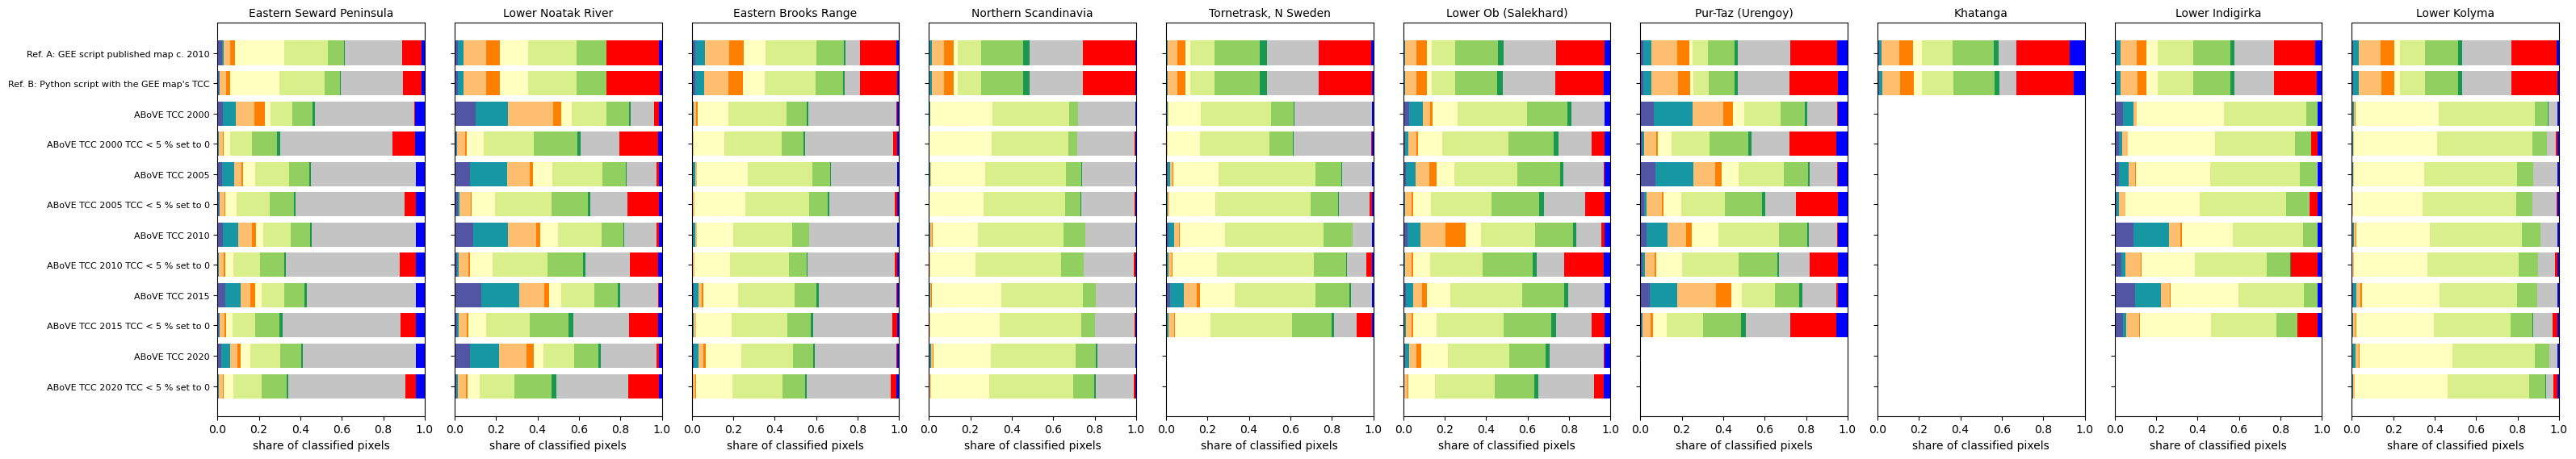

In [10]:
fig = tc.plot_composition(DISP, SITES, MAP_COLUMNS, LABELS)
plt.show()

## 8. Status of each run

In [11]:
pd.Series({f'{s} | {k}': v for (s, k), v in STATUS.items()}, name='status').to_frame()

,status
Eastern Seward Peninsula | gee_tcc,done
Eastern Seward Peninsula | above2000,done
Eastern Seward Peninsula | above2000_floor5,done
Eastern Seward Peninsula | above2001,done
Eastern Seward Peninsula | above2001_floor5,done
...,...
Lower Kolyma | above2018_floor5,done
Lower Kolyma | above2019,done
Lower Kolyma | above2019_floor5,done
Lower Kolyma | above2020,done
